In [4]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Exercise 1 – Image Enhancement and Intensity Transformations

## (a) Read and display the original grayscale image

In [5]:
img = cv2.imread("revision_gray.png", cv2.IMREAD_GRAYSCALE)

In [6]:
print("Shape:", img.shape)
print("Data type:", img.dtype)

Shape: (650, 980)
Data type: uint8


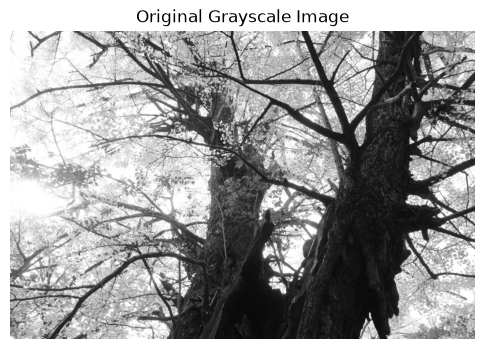

In [7]:
plt.figure(figsize=(6,5))
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

## (b) Brightness (+45) and negative image

In [8]:
brighter = np.clip(img.astype(np.int16) + 45, 0, 255).astype(np.uint8)
negative = 255 - img

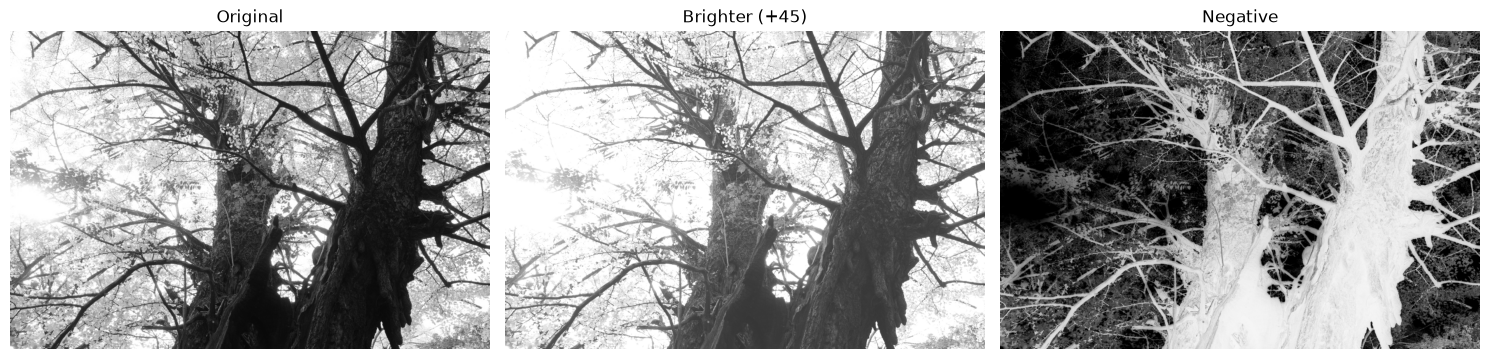

In [9]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(brighter, cmap="gray", vmin=0, vmax=255)
plt.title("Brighter (+45)")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(negative, cmap="gray", vmin=0, vmax=255)
plt.title("Negative")
plt.axis("off")

plt.tight_layout()
plt.show()

## (c) Gamma transformation (γ = 0.6, 1.0, 1.8)

In [10]:
normalized = img.astype(np.float32) / 255.0

In [11]:
gamma_06 = np.power(normalized, 0.6) * 255
gamma_06 = np.clip(gamma_06, 0, 255).astype(np.uint8)

gamma_10 = np.power(normalized, 1.0) * 255
gamma_10 = np.clip(gamma_10, 0, 255).astype(np.uint8)

gamma_18 = np.power(normalized, 1.8) * 255
gamma_18 = np.clip(gamma_18, 0, 255).astype(np.uint8)

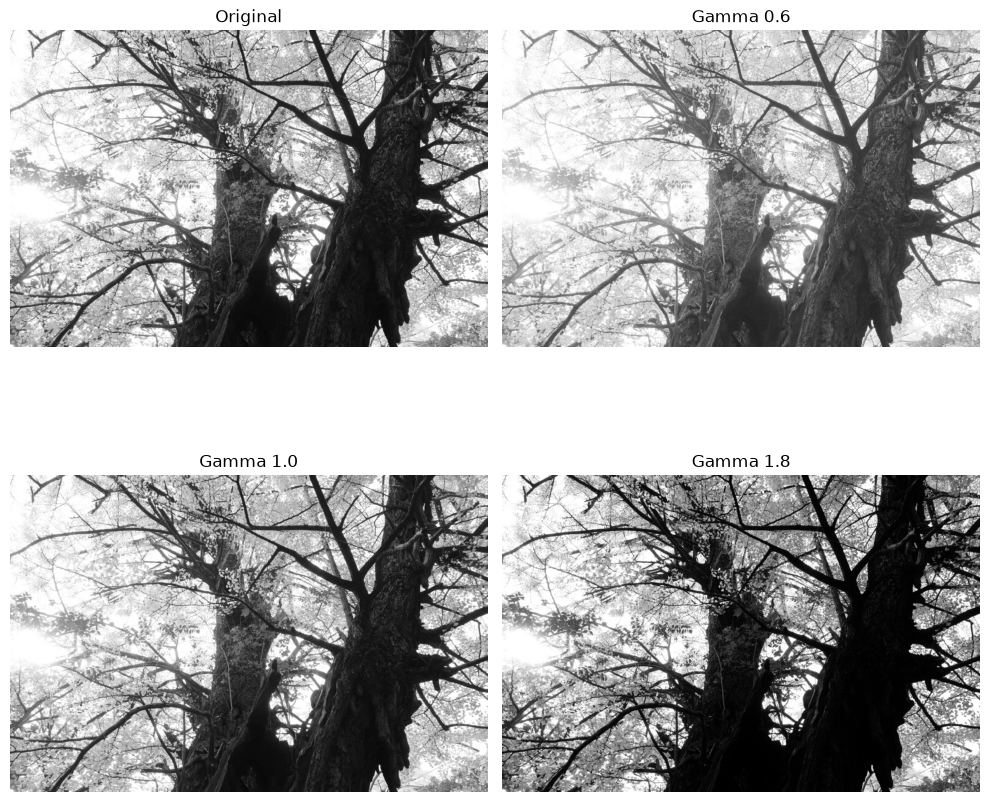

In [12]:
plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(gamma_06, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma 0.6")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(gamma_10, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma 1.0")
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(gamma_18, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma 1.8")
plt.axis("off")

plt.tight_layout()
plt.show()

## (d) Logarithmic transformation  s = c · log(1 + r)

In [13]:
img_float = img.astype(np.float32)

# choose c so that the maximum transformed intensity becomes 255
c = 255.0 / np.log1p(img_float.max())

log_transformed = c * np.log1p(img_float)
log_transformed = np.clip(log_transformed, 0, 255).astype(np.uint8)

print("c =", c)
print("Maximum after transformation:", log_transformed.max())

c = 45.985905
Maximum after transformation: 255


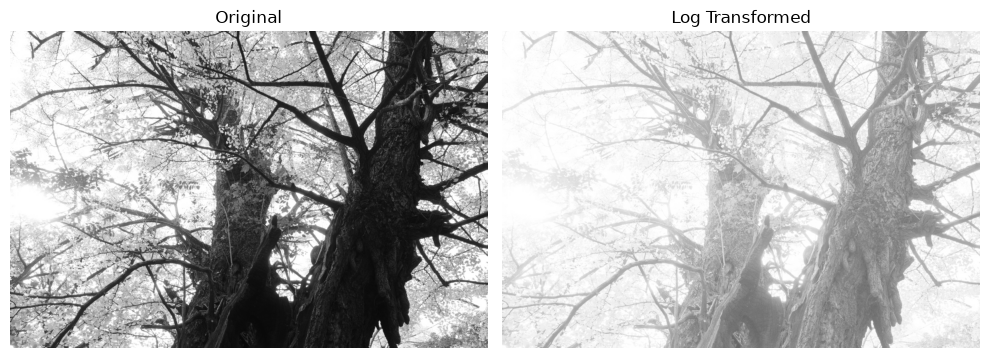

In [14]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(log_transformed, cmap="gray", vmin=0, vmax=255)
plt.title("Log Transformed")
plt.axis("off")

plt.tight_layout()
plt.show()

## (e) Threshold binarization – fixed (120) and Otsu

In [17]:
_, fixed_thresh = cv2.threshold(img, 120, 255, cv2.THRESH_BINARY)
otsu_value, otsu_thresh = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print("Otsu automatically selected threshold value:", otsu_value)

Otsu automatically selected threshold value: 129.0


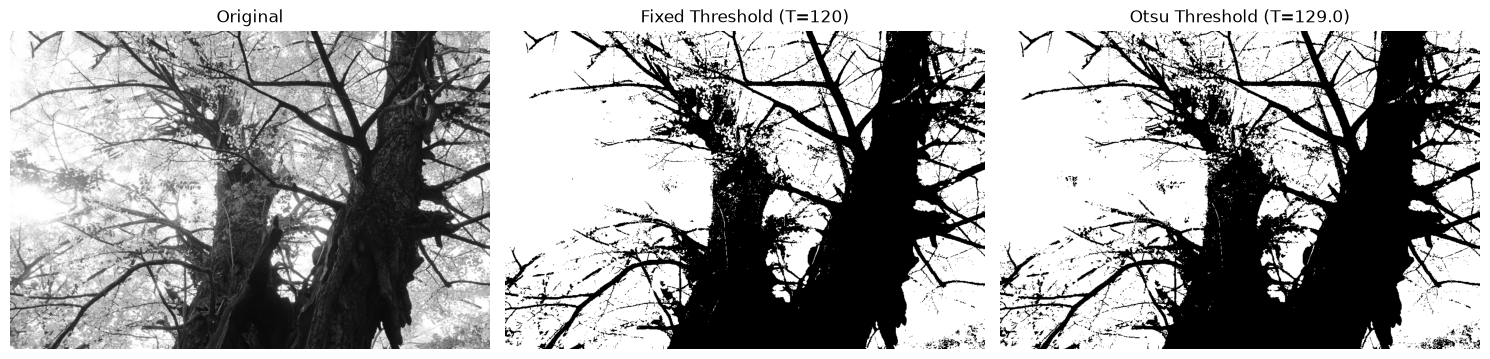

In [18]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(fixed_thresh, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Threshold (T=120)")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(otsu_thresh, cmap="gray", vmin=0, vmax=255)
plt.title(f"Otsu Threshold (T={otsu_value})")
plt.axis("off")

plt.tight_layout()
plt.show()

## (f) Histogram equalization with 256-bin histograms

In [19]:
eq_img = cv2.equalizeHist(img)

hist_orig, _ = np.histogram(img.flatten(), bins=256, range=(0,256))
hist_eq, _ = np.histogram(eq_img.flatten(), bins=256, range=(0,256))

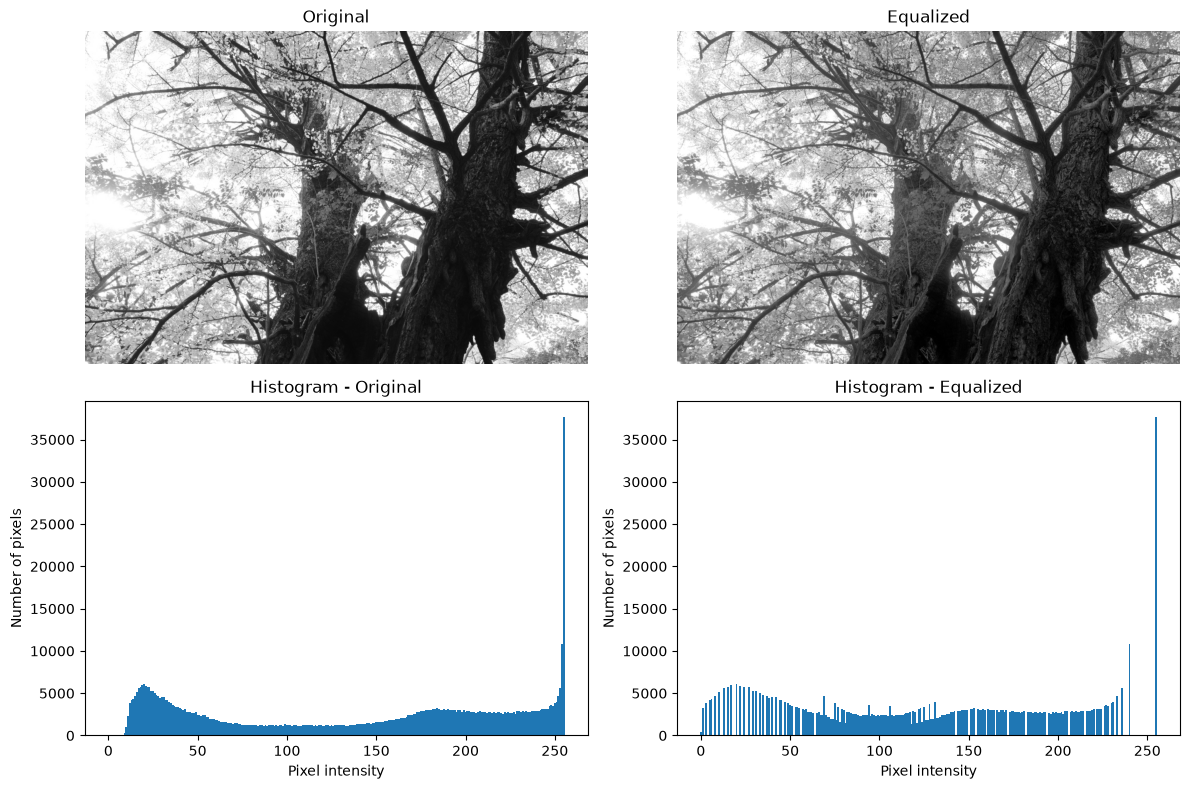

In [20]:
plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(eq_img, cmap="gray", vmin=0, vmax=255)
plt.title("Equalized")
plt.axis("off")

plt.subplot(2,2,3)
plt.bar(range(256), hist_orig, width=1)
plt.title("Histogram - Original")
plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")

plt.subplot(2,2,4)
plt.bar(range(256), hist_eq, width=1)
plt.title("Histogram - Equalized")
plt.xlabel("Pixel intensity")
plt.ylabel("Number of pixels")

plt.tight_layout()
plt.show()

# Exercise 2 – Colour Image Processing

## (a) Read and display the original colour image

In [22]:
color_img = cv2.imread("revision_colour.png")
color_rgb = cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB)

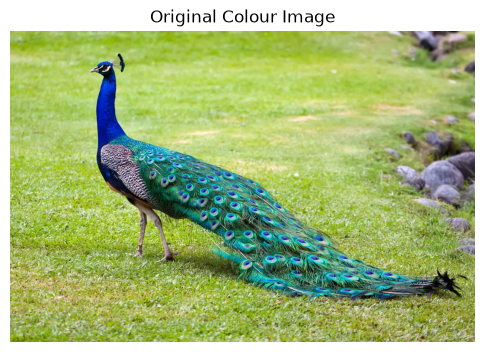

In [23]:
plt.figure(figsize=(6,5))
plt.imshow(color_rgb)
plt.title("Original Colour Image")
plt.axis("off")
plt.show()

## (b) Red, Green and Blue channels

In [24]:
red_channel = color_rgb[:,:,0]
green_channel = color_rgb[:,:,1]
blue_channel = color_rgb[:,:,2]

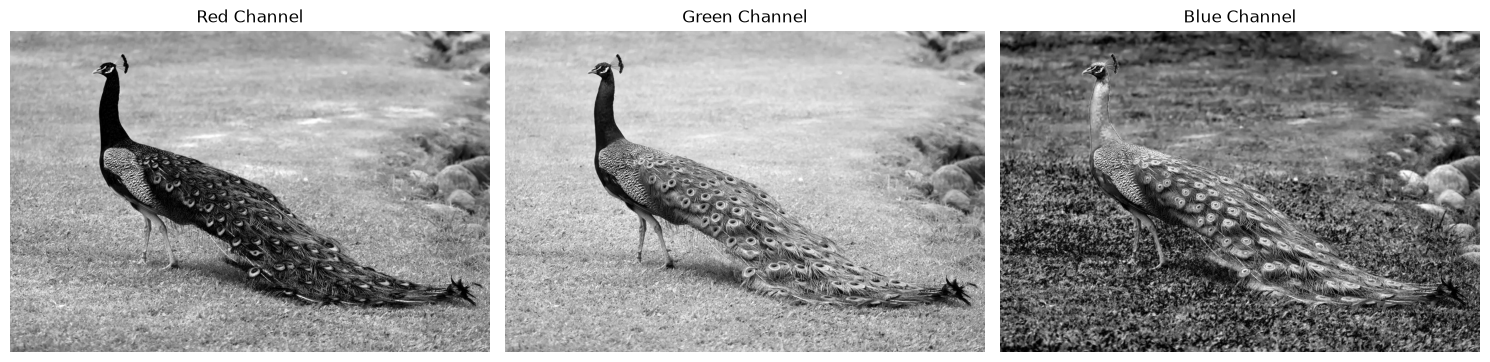

In [26]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(red_channel, cmap="gray", vmin=0, vmax=255)
plt.title("Red Channel")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(green_channel, cmap="gray", vmin=0, vmax=255)
plt.title("Green Channel")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(blue_channel, cmap="gray", vmin=0, vmax=255)
plt.title("Blue Channel")
plt.axis("off")

plt.tight_layout()
plt.show()

## (c) Colour-isolated images

In [ ]:
red_only = np.zeros_like(color_rgb)
red_only[:,:,0] = red_channel

green_only = np.zeros_like(color_rgb)
green_only[:,:,1] = green_channel

blue_only = np.zeros_like(color_rgb)
blue_only[:,:,2] = blue_channel

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(red_only)
plt.title("Red Only")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(green_only)
plt.title("Green Only")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(blue_only)
plt.title("Blue Only")
plt.axis("off")

plt.tight_layout()
plt.show()

## (d) HSV colour space – Hue, Saturation, Value

In [ ]:
hsv = cv2.cvtColor(color_img, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(h, cmap="gray")
plt.title("Hue")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(s, cmap="gray", vmin=0, vmax=255)
plt.title("Saturation")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(v, cmap="gray", vmin=0, vmax=255)
plt.title("Value")
plt.axis("off")

plt.tight_layout()
plt.show()

## (e) Histogram equalization on the Value channel

In [ ]:
v_eq = cv2.equalizeHist(v)

hsv_eq = cv2.merge([h, s, v_eq])
enhanced_rgb = cv2.cvtColor(hsv_eq, cv2.COLOR_HSV2RGB)

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(color_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(enhanced_rgb)
plt.title("Enhanced (V channel equalized)")
plt.axis("off")

plt.tight_layout()
plt.show()

## (f) Grayscale conversion and automatic contrast stretching

In [ ]:
gray_from_color = cv2.cvtColor(color_img, cv2.COLOR_BGR2GRAY)

stretched = cv2.normalize(gray_from_color, None, 0, 255, cv2.NORM_MINMAX)

print("Before stretching -> min:", gray_from_color.min(), "max:", gray_from_color.max())
print("After stretching -> min:", stretched.min(), "max:", stretched.max())

In [ ]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(gray_from_color, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(stretched, cmap="gray", vmin=0, vmax=255)
plt.title("Contrast Stretched")
plt.axis("off")

plt.tight_layout()
plt.show()

# Exercise 3 – Image Filtering and Edge Detection

In [ ]:
img = cv2.imread("revision_edges.png", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("revision_edges.png not found - place it next to this notebook")

## (a) Smoothing filters

In [ ]:
mean_3 = cv2.blur(img, (3, 3))
mean_5 = cv2.blur(img, (5, 5))
gaussian_5 = cv2.GaussianBlur(img, (5, 5), sigmaX=1.2)
median_5 = cv2.medianBlur(img, 5)

In [ ]:
plt.figure(figsize=(15,10))
plt.subplot(2,3,1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(2,3,2)
plt.imshow(mean_3, cmap="gray", vmin=0, vmax=255)
plt.title("3x3 Mean Filter")
plt.axis("off")

plt.subplot(2,3,3)
plt.imshow(mean_5, cmap="gray", vmin=0, vmax=255)
plt.title("5x5 Mean Filter")
plt.axis("off")

plt.subplot(2,3,4)
plt.imshow(gaussian_5, cmap="gray", vmin=0, vmax=255)
plt.title("5x5 Gaussian Filter (sigma=1.2)")
plt.axis("off")

plt.subplot(2,3,5)
plt.imshow(median_5, cmap="gray", vmin=0, vmax=255)
plt.title("5x5 Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

## (b) Laplacian kernel

In [ ]:
lap_kernal = np.array([[0,1,0],
                      [1,-4,1],
                      [0,1,0]], dtype=np.float32)

lap_manual = cv2.filter2D(img.astype(np.float32), -1, lap_kernal)
lap_display = cv2.convertScaleAbs(lap_manual)

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(lap_display, cmap="gray", vmin=0, vmax=255)
plt.title("Laplacian Edge Response")
plt.axis("off")
plt.show()

## (c) Sobel operator – horizontal, vertical and gradient magnitude

In [ ]:
sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)

sobel_x_display = cv2.convertScaleAbs(sobel_x)
sobel_y_display = cv2.convertScaleAbs(sobel_y)
sobel_mag_display = cv2.convertScaleAbs(sobel_magnitude)

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(sobel_x_display, cmap="gray", vmin=0, vmax=255)
plt.title("Sobel Horizontal (X)")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(sobel_y_display, cmap="gray", vmin=0, vmax=255)
plt.title("Sobel Vertical (Y)")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(sobel_mag_display, cmap="gray", vmin=0, vmax=255)
plt.title("Gradient Magnitude")
plt.axis("off")

plt.tight_layout()
plt.show()

## (d) Laplacian of Gaussian (7×7 Gaussian, σ = 1.5)

In [ ]:
gaussian_7 = cv2.GaussianBlur(img, (7, 7), sigmaX=1.5)
log_response = cv2.Laplacian(gaussian_7, cv2.CV_64F, ksize=3)
log_display = cv2.convertScaleAbs(log_response)

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(log_display, cmap="gray", vmin=0, vmax=255)
plt.title("LoG Edge Response")
plt.axis("off")
plt.show()

## (e) Canny edge detection (60, 140)

In [ ]:
canny_edges = cv2.Canny(img, 60, 140)

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(canny_edges, cmap="gray", vmin=0, vmax=255)
plt.title("Canny Edges (60, 140)")
plt.axis("off")
plt.show()

## (f) Original, Sobel, LoG and Canny together

In [ ]:
plt.figure(figsize=(15,4))
plt.subplot(1,4,1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(sobel_mag_display, cmap="gray", vmin=0, vmax=255)
plt.title("Sobel Magnitude")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(log_display, cmap="gray", vmin=0, vmax=255)
plt.title("LoG Response")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(canny_edges, cmap="gray", vmin=0, vmax=255)
plt.title("Canny Edge Map")
plt.axis("off")

plt.tight_layout()
plt.show()

# Exercise 4 – Morphological Image Processing

## (a) Read the image and convert to binary (threshold = 127)

In [ ]:
img = cv2.imread("revision_shapes.png", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("revision_shapes.png not found - place it next to this notebook")

_, binary = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Binary Image (T=127)")
plt.axis("off")
plt.show()

## (b) Erosion and dilation (3×3 square structuring element)

In [ ]:
kernal = np.ones((3,3), np.uint8)

eroded_cv2 = cv2.erode(binary, kernal, iterations=1)
dilated_cv2 = cv2.dilate(binary, kernal, iterations=1)

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(eroded_cv2, cmap="gray", vmin=0, vmax=255)
plt.title("Erosion (3x3)")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(dilated_cv2, cmap="gray", vmin=0, vmax=255)
plt.title("Dilation (3x3)")
plt.axis("off")

plt.tight_layout()
plt.show()

## (c) Opening and closing (5×5 square structuring element)

In [ ]:
kernal_5 = np.ones((5,5), np.uint8)

opened_cv2 = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernal_5)
closed_cv2 = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernal_5)

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(opened_cv2, cmap="gray", vmin=0, vmax=255)
plt.title("Opening (5x5)")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(closed_cv2, cmap="gray", vmin=0, vmax=255)
plt.title("Closing (5x5)")
plt.axis("off")

plt.tight_layout()
plt.show()

## (d) Boundary extraction using erosion and subtraction

In [ ]:
boundary = cv2.subtract(binary, cv2.erode(binary, kernal, iterations=1))

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(boundary, cmap="gray", vmin=0, vmax=255)
plt.title("Boundary (Original - Erosion)")
plt.axis("off")
plt.show()

## (e) Outer boundaries using contour detection

In [ ]:
contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

contour_img = np.zeros_like(binary)
cv2.drawContours(contour_img, contours, -1, 255, 1)

print("Number of outer contours found:", len(contours))

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(contour_img, cmap="gray", vmin=0, vmax=255)
plt.title("Outer Contours")
plt.axis("off")
plt.show()

## (f) Comparison of the boundary images in (d) and (e)

In [ ]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(boundary, cmap="gray", vmin=0, vmax=255)
plt.title("Boundary (Erosion + Subtraction)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(contour_img, cmap="gray", vmin=0, vmax=255)
plt.title("Outer Contours")
plt.axis("off")

plt.tight_layout()
plt.show()

**Comparison:** The erosion-and-subtraction method (d) extracts *all* boundaries of the objects, including the inner boundaries of any holes, and the boundary thickness depends on the structuring element. The contour method (e) with `cv2.RETR_EXTERNAL` extracts only the *outer* boundary of each object as a 1-pixel line, so holes inside objects are ignored.

# Exercise 5 – Additional Practice: Image Arithmetic

## (a) Read and display both images

In [ ]:
img1 = cv2.imread("revision_image1.png", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("revision_image2.png", cv2.IMREAD_GRAYSCALE)
if img1 is None or img2 is None:
    raise FileNotFoundError("revision_image1.png / revision_image2.png not found - place them next to this notebook")

print(img1.shape)
print(img2.shape)

In [ ]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img1, cmap="gray", vmin=0, vmax=255)
plt.title("Image 1")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img2, cmap="gray", vmin=0, vmax=255)
plt.title("Image 2")
plt.axis("off")

plt.tight_layout()
plt.show()

## (b) Absolute difference – manual NumPy

In [ ]:
diff_manual = np.abs(img1.astype(np.int16) - img2.astype(np.int16))
diff_manual = np.clip(diff_manual, 0, 255).astype(np.uint8)

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(diff_manual, cmap="gray", vmin=0, vmax=255)
plt.title("Absolute Difference (Manual NumPy)")
plt.axis("off")
plt.show()

## (c) Absolute difference – cv2.absdiff()

In [ ]:
diff_cv2 = cv2.absdiff(img1, img2)

In [ ]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(diff_manual, cmap="gray", vmin=0, vmax=255)
plt.title("Absolute Difference (Manual)")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(diff_cv2, cmap="gray", vmin=0, vmax=255)
plt.title("Absolute Difference (cv2.absdiff)")
plt.axis("off")

plt.tight_layout()
plt.show()

## (d) Replace pixels > 180 in image 1 with pixels from image 2

In [ ]:
replaced = img1.copy()
mask = img1 > 180
replaced[mask] = img2[mask]

In [ ]:
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(img1, cmap="gray", vmin=0, vmax=255)
plt.title("Image 1")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(replaced, cmap="gray", vmin=0, vmax=255)
plt.title("Pixels > 180 replaced from Image 2")
plt.axis("off")

plt.tight_layout()
plt.show()

## (e) Addition of the two images (kept within 0–255)

In [ ]:
added = np.clip(img1.astype(np.int16) + img2.astype(np.int16), 0, 255).astype(np.uint8)

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(added, cmap="gray", vmin=0, vmax=255)
plt.title("Image 1 + Image 2 (clipped)")
plt.axis("off")
plt.show()

## (f) Subtraction (Image 1 − Image 2) with negative values handled

In [ ]:
# negative values are clipped to 0
subtracted = np.clip(img1.astype(np.int16) - img2.astype(np.int16), 0, 255).astype(np.uint8)

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(subtracted, cmap="gray", vmin=0, vmax=255)
plt.title("Image 1 - Image 2 (negatives clipped to 0)")
plt.axis("off")
plt.show()

# Final Revision Challenge

In [ ]:
# 1. Read and display the image
img = cv2.imread("revision_gray.png", cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("revision_gray.png not found - place it next to this notebook")

# 2. Histogram equalization
equalized = cv2.equalizeHist(img)

# 3. Gaussian smoothing
smoothed = cv2.GaussianBlur(equalized, (5, 5), sigmaX=1.2)

# 4. Laplacian sharpening
lap = cv2.Laplacian(smoothed.astype(np.float32), cv2.CV_32F, ksize=1)
sharpened = np.clip(smoothed.astype(np.float32) - lap, 0, 255).astype(np.uint8)

# 5. Canny edge detection
final_edges = cv2.Canny(sharpened, 100, 200)

In [ ]:
plt.figure(figsize=(15,8))
plt.subplot(2,3,1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original")
plt.axis("off")

plt.subplot(2,3,2)
plt.imshow(equalized, cmap="gray", vmin=0, vmax=255)
plt.title("Histogram Equalized")
plt.axis("off")

plt.subplot(2,3,3)
plt.imshow(smoothed, cmap="gray", vmin=0, vmax=255)
plt.title("Gaussian Smoothed")
plt.axis("off")

plt.subplot(2,3,4)
plt.imshow(sharpened, cmap="gray", vmin=0, vmax=255)
plt.title("Laplacian Sharpened")
plt.axis("off")

plt.subplot(2,3,5)
plt.imshow(final_edges, cmap="gray", vmin=0, vmax=255)
plt.title("Canny Edges (Final)")
plt.axis("off")

plt.tight_layout()
plt.show()